# Diabetes Disease Progression Regression Study

## Objective

The objective of this project is to build and evaluate machine learning models for predicting a quantitative measure of diabetes disease progression one year after baseline measurement.

This is a regression problem. The target variable is continuous, so the modelling objective is to learn a function:

```text
f : R^10 -> R
```

such that:

```text
y_hat = f(x)
```

provides an accurate estimate of disease progression from the patient's baseline characteristics.

## Research Questions

1. Which baseline characteristics have the strongest association with disease progression?
2. How well can a linear model explain the variation in the target?
3. Does regularization improve generalization when predictors are correlated?
4. Do nonlinear feature transformations capture relationships missed by a linear model?
5. How sensitive are conclusions to model choice?
6. Which model provides the best balance between predictive accuracy and interpretability?

In [1]:
# Core imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)

## 1. Load Dataset

The scikit-learn diabetes dataset has 442 observations and 10 baseline features.

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

feature_descriptions = {
    "age": "Age of the individual",
    "sex": "Sex of the individual",
    "bmi": "Body Mass Index",
    "bp": "Average blood pressure",
    "s1": "Total serum cholesterol",
    "s2": "Low-density lipoproteins (LDL)",
    "s3": "High-density lipoproteins (HDL)",
    "s4": "Total cholesterol / HDL ratio",
    "s5": "Log-transformed serum triglycerides level",
    "s6": "Blood sugar level",
}

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (442, 10)
y shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [3]:
pd.DataFrame({
    "feature": list(feature_descriptions.keys()),
    "description": list(feature_descriptions.values())
})

,feature,description
0,age,Age of the individual
1,sex,Sex of the individual
2,bmi,Body Mass Index
3,bp,Average blood pressure
4,s1,Total serum cholesterol
5,s2,Low-density lipoproteins (LDL)
6,s3,High-density lipoproteins (HDL)
7,s4,Total cholesterol / HDL ratio
8,s5,Log-transformed serum triglycerides level
9,s6,Blood sugar level


## 2. Exploratory Data Analysis

We inspect summary statistics, target distribution, feature-target correlations, and feature-feature correlations.

In [4]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


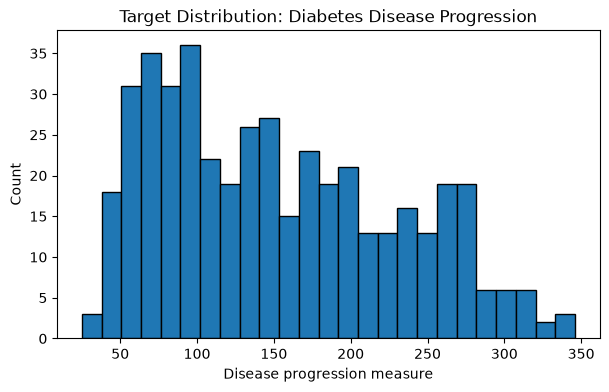

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y, bins=25, edgecolor="black")
ax.set_title("Target Distribution: Diabetes Disease Progression")
ax.set_xlabel("Disease progression measure")
ax.set_ylabel("Count")
plt.show()

In [6]:
eda_df = X.copy()
eda_df["target"] = y

corr_with_target = eda_df.corr()["target"].drop("target").sort_values(key=lambda s: s.abs(), ascending=False)
corr_with_target.to_frame("correlation_with_target")

,correlation_with_target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


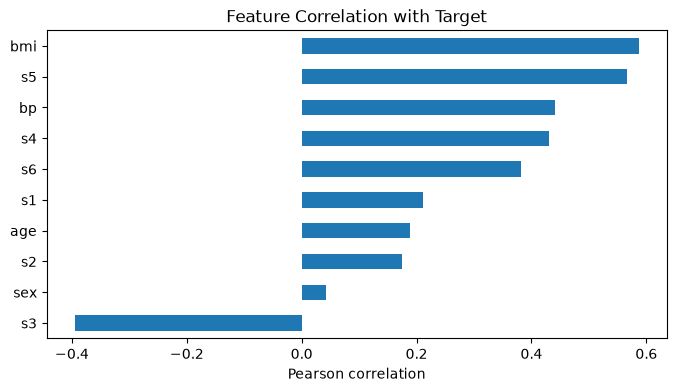

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
corr_with_target.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Feature Correlation with Target")
ax.set_xlabel("Pearson correlation")
plt.show()

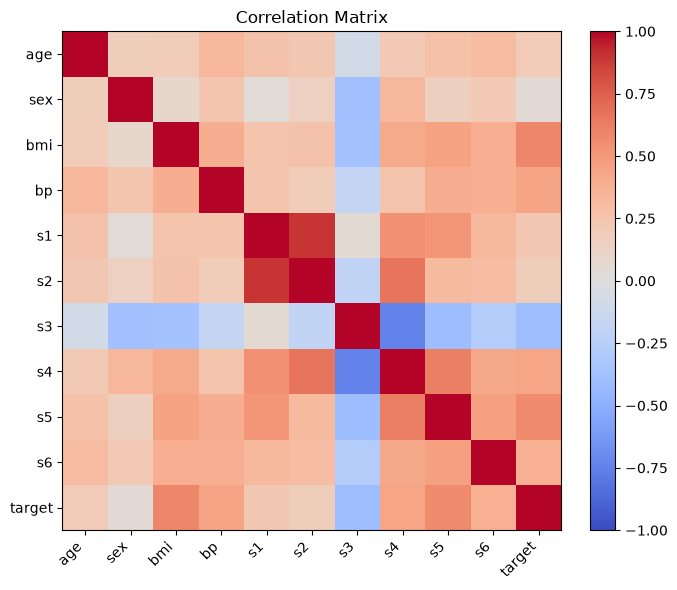

In [8]:
# Correlation matrix using matplotlib only, to avoid extra dependencies.
corr = eda_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Matrix")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

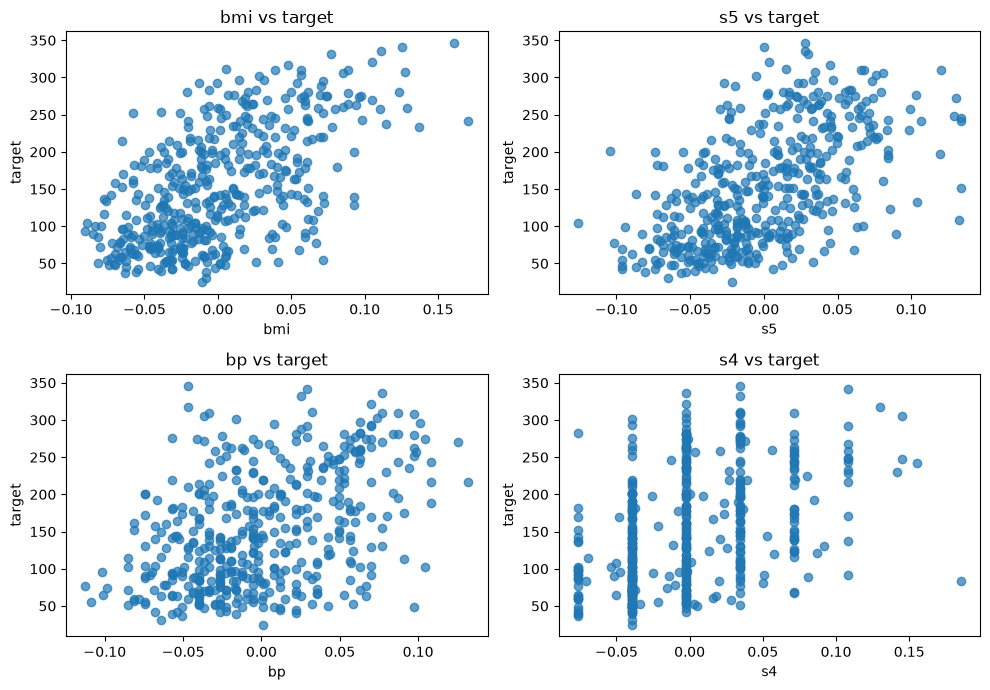

In [9]:
# Scatter plots for the strongest target-associated features.
top_features = corr_with_target.abs().head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.ravel()
for ax, feature in zip(axes, top_features):
    ax.scatter(X[feature], y, alpha=0.7)
    ax.set_title(f"{feature} vs target")
    ax.set_xlabel(feature)
    ax.set_ylabel("target")
plt.tight_layout()
plt.show()

## 3. Train-Test Split

The test set is kept separate until final evaluation. Model selection and hyperparameter tuning are performed only on the training set through cross-validation.

```text
D = D_train union D_test, with D_train intersection D_test = empty set
```

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 353
Test samples: 89


## 4. Evaluation Helpers

We evaluate models using RMSE, MAE, and R^2.

```text
RMSE = sqrt((1/n) sum_i (y_i - y_hat_i)^2)
MAE  = (1/n) sum_i |y_i - y_hat_i|
R^2  = 1 - RSS/TSS
```

In [11]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

## 5. Baseline Linear Models

We compare ordinary least squares, Ridge, and Lasso using the original 10 features.

OLS minimizes:

```text
RSS = sum_i (y_i - y_hat_i)^2
```

Ridge minimizes:

```text
RSS + alpha * sum_j beta_j^2
```

Lasso minimizes:

```text
RSS + alpha * sum_j |beta_j|
```

Ridge shrinks coefficients. Lasso can shrink some coefficients exactly to zero, making it useful for feature selection.

In [12]:
models_original = {
    "OLS": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=100000))
    ]),
}

param_grids_original = {
    "OLS": {},
    "Ridge": {"model__alpha": np.logspace(-3, 3, 25)},
    "Lasso": {"model__alpha": np.logspace(-3, 2, 25)},
}

In [13]:
def fit_grid_searches(models, param_grids, X_train, y_train, cv):
    fitted = {}
    rows = []

    for name, pipe in models.items():
        grid = GridSearchCV(
            pipe,
            param_grids[name],
            scoring="neg_root_mean_squared_error",
            cv=cv,
            n_jobs=-1,
            refit=True,
        )
        grid.fit(X_train, y_train)
        fitted[name] = grid
        rows.append({
            "model": name,
            "best_params": grid.best_params_,
            "cv_rmse": -grid.best_score_,
        })

    return fitted, pd.DataFrame(rows).sort_values("cv_rmse")

fitted_original, cv_results_original = fit_grid_searches(
    models_original, param_grids_original, X_train, y_train, cv
)
cv_results_original

,model,best_params,cv_rmse
2,Lasso,{'model__alpha': 0.510896977450693},55.350604
1,Ridge,{'model__alpha': 1.0},55.374175
0,OLS,{},55.394633


## 6. Feature-Engineered Regression

We add polynomial and interaction features using `PolynomialFeatures`.

For degree 2, the expanded set includes terms such as:

```text
x_i^2 and x_i x_j
```

For degree 3, it also includes cubic and higher interaction terms:

```text
x_i^3, x_i^2 x_j, x_i x_j x_k
```

Increasing degree increases flexibility, but it can also increase overfitting risk.

In [14]:
def make_poly_pipeline(model, degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

models_poly = {}
param_grids_poly = {}

for degree in [2, 3]:
    models_poly[f"OLS_poly{degree}"] = make_poly_pipeline(LinearRegression(), degree)
    param_grids_poly[f"OLS_poly{degree}"] = {}

    models_poly[f"Ridge_poly{degree}"] = make_poly_pipeline(Ridge(), degree)
    param_grids_poly[f"Ridge_poly{degree}"] = {"model__alpha": np.logspace(-3, 4, 30)}

    models_poly[f"Lasso_poly{degree}"] = make_poly_pipeline(Lasso(max_iter=200000), degree)
    param_grids_poly[f"Lasso_poly{degree}"] = {"model__alpha": np.logspace(-3, 2, 30)}

In [15]:
fitted_poly, cv_results_poly = fit_grid_searches(
    models_poly, param_grids_poly, X_train, y_train, cv
)
cv_results_poly

,model,best_params,cv_rmse
2,Lasso_poly2,{'model__alpha': 2.8072162039411785},56.027932
1,Ridge_poly2,{'model__alpha': 67.23357536499334},56.915155
5,Lasso_poly3,{'model__alpha': 6.2101694189156165},57.289518
4,Ridge_poly3,{'model__alpha': 621.0169418915616},59.272921
0,OLS_poly2,{},62.504792
3,OLS_poly3,{},1402.176901


## 7. Cross-Validation Summary

We combine the original-feature models and feature-engineered models to compare expected generalization performance before touching the test set.

In [16]:
cv_summary = pd.concat([cv_results_original, cv_results_poly], ignore_index=True)
cv_summary = cv_summary.sort_values("cv_rmse").reset_index(drop=True)
cv_summary

,model,best_params,cv_rmse
0,Lasso,{'model__alpha': 0.510896977450693},55.350604
1,Ridge,{'model__alpha': 1.0},55.374175
2,OLS,{},55.394633
3,Lasso_poly2,{'model__alpha': 2.8072162039411785},56.027932
4,Ridge_poly2,{'model__alpha': 67.23357536499334},56.915155
5,Lasso_poly3,{'model__alpha': 6.2101694189156165},57.289518
6,Ridge_poly3,{'model__alpha': 621.0169418915616},59.272921
7,OLS_poly2,{},62.504792
8,OLS_poly3,{},1402.176901


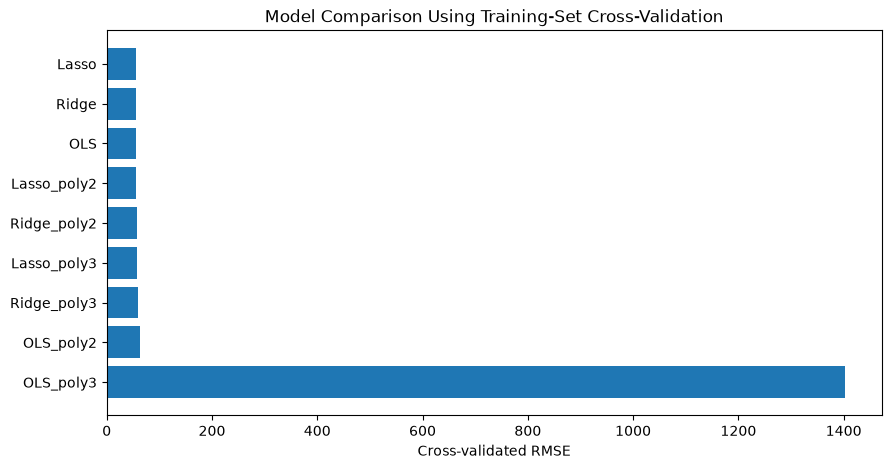

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = cv_summary.sort_values("cv_rmse", ascending=True)
ax.barh(plot_df["model"], plot_df["cv_rmse"])
ax.invert_yaxis()
ax.set_xlabel("Cross-validated RMSE")
ax.set_title("Model Comparison Using Training-Set Cross-Validation")
plt.show()

## 8. Final Test Evaluation

Only after model selection do we evaluate on the held-out test set.

In [18]:
all_fitted = {**fitted_original, **fitted_poly}

test_rows = []
for name, grid in all_fitted.items():
    pred = grid.best_estimator_.predict(X_test)
    metrics = regression_metrics(y_test, pred)
    test_rows.append({
        "model": name,
        "best_params": grid.best_params_,
        **metrics,
    })

test_results = pd.DataFrame(test_rows).sort_values("RMSE").reset_index(drop=True)
test_results

,model,best_params,RMSE,MAE,R2
0,Lasso_poly2,{'model__alpha': 2.8072162039411785},50.520446,41.057389,0.518263
1,Ridge_poly2,{'model__alpha': 67.23357536499334},51.171858,40.859214,0.505760
2,Lasso_poly3,{'model__alpha': 6.2101694189156165},52.718368,43.714591,0.475435
3,Lasso,{'model__alpha': 0.510896977450693},53.447812,42.838671,0.460818
4,Ridge,{'model__alpha': 1.0},53.777454,42.811999,0.454147
5,OLS,{},53.853446,42.794095,0.452603
6,OLS_poly2,{},55.641965,43.581693,0.415640
7,Ridge_poly3,{'model__alpha': 621.0169418915616},55.712622,46.010733,0.414155
8,OLS_poly3,{},278.942291,161.189564,-13.686027


Best test model: Lasso_poly2
{'RMSE': np.float64(50.52044595809918), 'MAE': 41.057388806985145, 'R2': 0.5182630507856201}


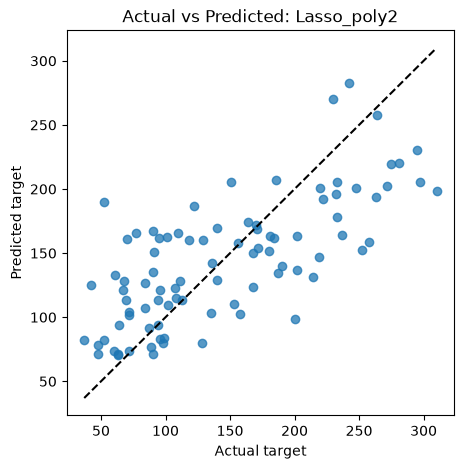

In [20]:
best_model_name = test_results.loc[0, "model"]
best_model = all_fitted[best_model_name].best_estimator_
y_pred_best = best_model.predict(X_test)

print("Best test model:", best_model_name)
print(regression_metrics(y_test, y_pred_best))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, y_pred_best, alpha=0.75)
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
ax.plot(lims, lims, "--", color="black")
ax.set_xlabel("Actual target")
ax.set_ylabel("Predicted target")
ax.set_title(f"Actual vs Predicted: {best_model_name}")
plt.show()

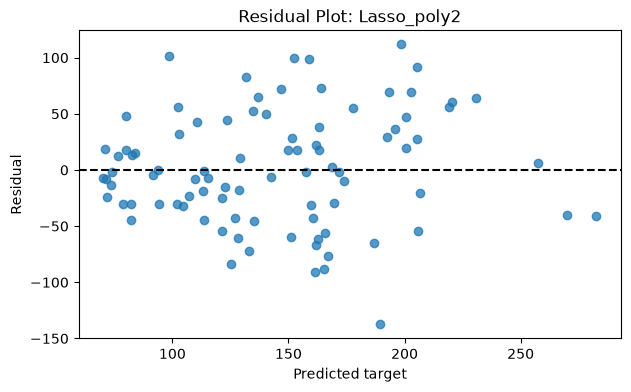

In [21]:
residuals = y_test - y_pred_best

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(y_pred_best, residuals, alpha=0.75)
ax.axhline(0, linestyle="--", color="black")
ax.set_xlabel("Predicted target")
ax.set_ylabel("Residual")
ax.set_title(f"Residual Plot: {best_model_name}")
plt.show()

## 9. Coefficient Interpretation

For linear models, coefficients help interpret how each feature is associated with the target. Since scaling is used inside the pipeline, coefficients are comparable in standardized units.

For polynomial models, coefficients are harder to interpret because features include powers and interactions.

In [22]:
def coefficient_table_from_pipeline(grid, original_feature_names):
    estimator = grid.best_estimator_
    steps = estimator.named_steps
    model = steps["model"]

    if "poly" in steps:
        feature_names = steps["poly"].get_feature_names_out(original_feature_names)
    else:
        feature_names = np.array(original_feature_names)

    coefs = getattr(model, "coef_", None)
    if coefs is None:
        return None

    return (
        pd.DataFrame({"feature": feature_names, "coefficient": coefs})
        .assign(abs_coefficient=lambda df: df["coefficient"].abs())
        .sort_values("abs_coefficient", ascending=False)
        .reset_index(drop=True)
    )

for name in ["OLS", "Ridge", "Lasso"]:
    print("\n", name)
    display(coefficient_table_from_pipeline(fitted_original[name], X.columns).head(10))


 OLS


,feature,coefficient,abs_coefficient
0,s1,-44.448856,44.448856
1,s5,35.161195,35.161195
2,bmi,25.607121,25.607121
3,s2,24.640954,24.640954
4,bp,16.828872,16.828872
5,s4,13.138784,13.138784
6,sex,-11.511809,11.511809
7,s3,7.676978,7.676978
8,s6,2.351364,2.351364
9,age,1.753758,1.753758



 Ridge


,feature,coefficient,abs_coefficient
0,s1,-34.671954,34.671954
1,s5,31.378384,31.378384
2,bmi,25.732699,25.732699
3,s2,17.053075,17.053075
4,bp,16.734300,16.734300
5,s4,11.764260,11.764260
6,sex,-11.448190,11.448190
7,s3,3.369914,3.369914
8,s6,2.458139,2.458139
9,age,1.807342,1.807342



 Lasso


,feature,coefficient,abs_coefficient
0,bmi,26.225969,26.225969
1,s5,23.074963,23.074963
2,bp,16.157722,16.157722
3,s1,-11.587822,11.587822
4,sex,-10.366915,10.366915
5,s4,7.365915,7.365915
6,s3,-6.489456,6.489456
7,s6,2.324523,2.324523
8,age,1.327926,1.327926
9,s2,0.000000,0.000000


In [23]:
# If the best model is a Lasso model, inspect selected nonzero features.
if "Lasso" in best_model_name:
    coef_table = coefficient_table_from_pipeline(all_fitted[best_model_name], X.columns)
    selected = coef_table[coef_table["coefficient"].abs() > 1e-8]
    print("Selected features:", len(selected))
    display(selected.head(20))
else:
    coef_table = coefficient_table_from_pipeline(all_fitted[best_model_name], X.columns)
    if coef_table is not None:
        display(coef_table.head(20))

Selected features: 18


,feature,coefficient,abs_coefficient
0,bmi,23.987357,23.987357
1,s5,19.616675,19.616675
2,bp,13.769219,13.769219
3,s3,-10.478272,10.478272
4,sex^2,-6.059093,6.059093
5,age sex,4.390308,4.390308
6,bmi^2,3.363712,3.363712
7,bmi bp,2.902511,2.902511
8,s6^2,2.141784,2.141784
9,age s5,1.412378,1.412378


## 10. Discussion Guide

Use the outputs above to answer the research questions:

1. Strongest associations are identified by feature-target correlations and model coefficients.
2. OLS performance shows how much variation is explained by a linear model.
3. Ridge and Lasso show whether regularization improves cross-validated and test RMSE.
4. Polynomial models test whether nonlinear transformations and interactions help.
5. Comparing coefficient patterns and test scores reveals sensitivity to model choice.
6. The best practical model should balance low prediction error with interpretability.

## 11. Conclusion Template

A concise final conclusion can be written as:

```text
The diabetes regression study shows that feature representation and regularization both affect predictive performance. The original linear models provide a clear and interpretable baseline, while polynomial feature engineering increases flexibility by adding nonlinear and interaction terms. Ridge regression is useful when correlated predictors or engineered terms make OLS unstable, while Lasso can improve interpretability by selecting a smaller subset of useful features. The best model should be chosen based on cross-validation and confirmed once on the test set, with attention to both RMSE/R^2 and interpretability.
```